# 03 — K-Means berbasis skor TOPSIS
Input: `data/dki_master.csv` + `data/topsis_result.csv` · Output: `data/clustered_result.csv`

## 1. Setup & load data

In [ ]:
import warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, geopandas as gpd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

ROOT = Path(".."); DATA = ROOT/"data"; FIG = DATA/"figures"; FIG.mkdir(parents=True, exist_ok=True)
SEED = 42

master = pd.read_csv(DATA/"dki_master.csv", index_col="kecamatan")
topsis = pd.read_csv(DATA/"topsis_result.csv"); topsis["kecamatan"] = topsis.kecamatan.str.strip().str.upper(); topsis = topsis.set_index("kecamatan")

base = master.drop(index=[k for k in master.index if "SERIBU" in k])      # 42 kecamatan (sama dengan TOPSIS)
base = base.join(topsis[["skor_topsis","rank_topsis"]], how="left")
assert base.skor_topsis.notna().all(), f"kecamatan tanpa skor TOPSIS: {base.index[base.skor_topsis.isna()].tolist()}"
print(base.shape, "| skor TOPSIS cocok 42/42")

(42, 20) | skor TOPSIS cocok 42/42


## 2. Pilih fitur & preprocessing
`skor_topsis` merangkum 6 kriteria risiko. Fitur pendamping dipilih yang **bukan** kriteria TOPSIS agar tidak terhitung dua kali.

In [ ]:
CAND = ["skor_topsis",                                                           # hasil SPK
        "frek_tahun_banjir", "kejadian_per_tahun", "tinggi_med_cm",              # pelengkap banjir (bukan kriteria TOPSIS)
        "pertumbuhan_pddk_15_19"]                                                # pelengkap demografi
X = base[CAND].copy(); X = X.fillna(X.median()); print(X.describe().T.round(2))

                        count   mean    std    min    25%    50%    75%     max
skor_topsis              42.0   0.40   0.20   0.03   0.26   0.41   0.55    0.89
frek_tahun_banjir        42.0   0.84   0.22   0.25   0.75   1.00   1.00    1.00
kejadian_per_tahun       42.0   7.46   5.89   0.50   2.44   6.62  10.69   22.62
tinggi_med_cm            42.0  51.96  15.02  20.00  40.62  50.00  60.00  100.00
pertumbuhan_pddk_15_19   42.0   0.04   0.15  -0.61   0.05   0.07   0.10    0.15


outlier: {'frek_tahun_banjir': 2, 'tinggi_med_cm': 2, 'pertumbuhan_pddk_15_19': 2}
log1p: []
dibuang (r>0.9): ['kejadian_per_tahun']
FEATURES: ['skor_topsis', 'frek_tahun_banjir', 'tinggi_med_cm', 'pertumbuhan_pddk_15_19']


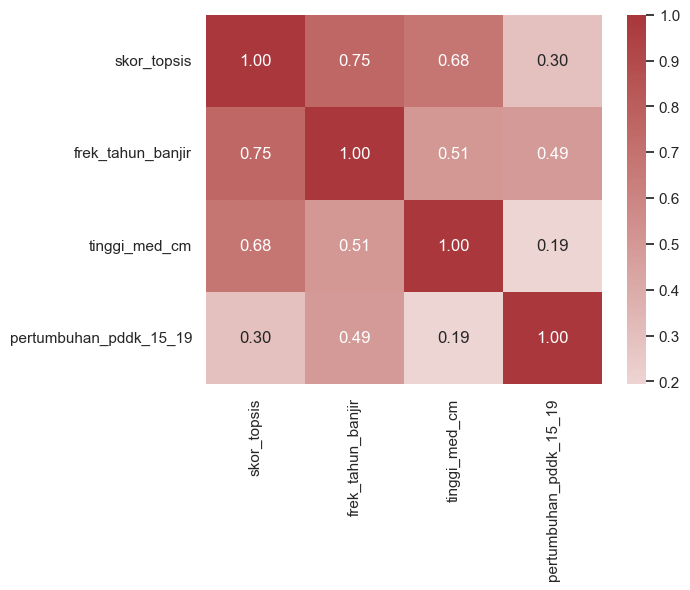

In [ ]:
q1, q3 = X.quantile(.25), X.quantile(.75); out = (X < q1-1.5*(q3-q1)) | (X > q3+1.5*(q3-q1))
print("outlier:", out.sum()[out.sum() > 0].to_dict())

LOG = [k for k in X.columns if k != "skor_topsis" and X[k].skew() > 1 and (X[k] >= 0).all()]
Xt = X.copy(); Xt[LOG] = np.log1p(Xt[LOG]); print("log1p:", LOG)
for k in X.columns[out.any()]:
    if k != "skor_topsis": lo, hi = Xt[k].quantile([.05, .95]); Xt[k] = Xt[k].clip(lo, hi)       # winsorize 5%

cr = Xt.corr().abs(); drop = set()
for i, a_ in enumerate(cr.columns):
    for b_ in cr.columns[i+1:]:
        if cr.loc[a_, b_] > 0.90 and a_ not in drop and b_ not in drop: drop.add(b_)
FEATURES = [k for k in Xt.columns if k not in drop]; print("dibuang (r>0.9):", sorted(drop)); print("FEATURES:", FEATURES)

Z = pd.DataFrame(StandardScaler().fit_transform(Xt[FEATURES]), index=Xt.index, columns=FEATURES)
sns.heatmap(Xt[FEATURES].corr(), annot=True, fmt=".2f", cmap="vlag", center=0); plt.show()

## 3. Pilih k

,inertia,silhouette,DBI,CH
k,,,,
2,93.403,0.361,1.057,31.946
3,69.694,0.326,1.025,27.505
4,48.273,0.339,0.953,31.416
5,38.649,0.352,0.942,30.958
6,33.490,0.321,0.972,28.918
7,29.128,0.316,0.915,27.811
8,26.101,0.287,1.000,26.406


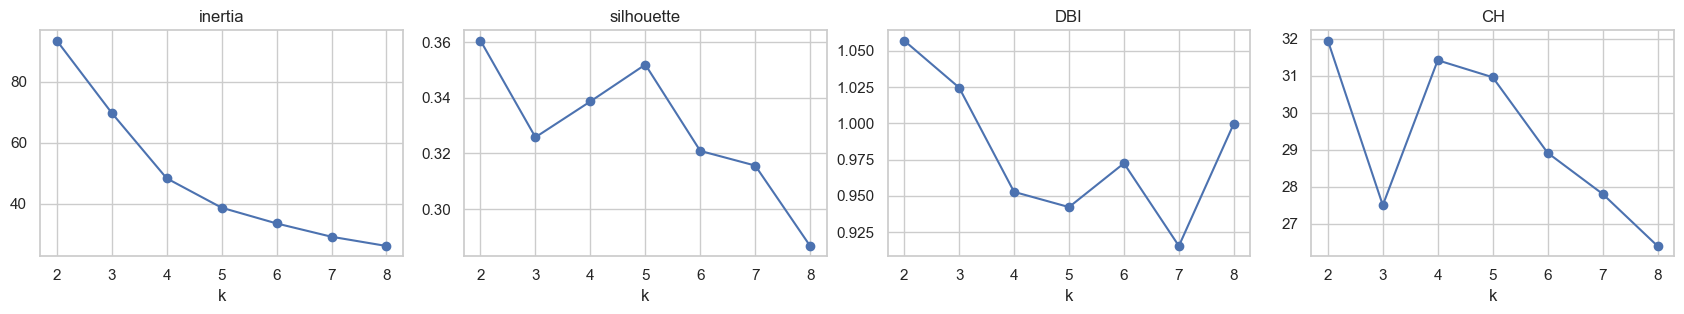

In [ ]:
rows = []
for k in range(2, 9):
    l = KMeans(k, n_init=50, random_state=SEED).fit(Z)
    rows.append(dict(k=k, inertia=l.inertia_, silhouette=silhouette_score(Z, l.labels_), DBI=davies_bouldin_score(Z, l.labels_), CH=calinski_harabasz_score(Z, l.labels_)))
sel = pd.DataFrame(rows).set_index("k"); display(sel.round(3))
fig, ax = plt.subplots(1, 4, figsize=(17, 3.3))
for i, k in enumerate(sel.columns): sel[k].plot(marker="o", ax=ax[i], title=k)
plt.tight_layout(); plt.savefig(FIG/"pilih_k.png", dpi=200); plt.show()

## 4. K-Means final & validasi

In [ ]:
K_FINAL = 4
km = KMeans(K_FINAL, n_init=100, random_state=SEED).fit(Z)

# urutkan cluster: id 0 = rata-rata skor TOPSIS tertinggi (risiko tertinggi) ... id K-1 = terendah
order = pd.Series(base.skor_topsis.values).groupby(km.labels_).mean().sort_values(ascending=False).index.tolist()
labels  = np.array([order.index(l) for l in km.labels_]); centers = km.cluster_centers_[order]

res = base.copy(); res["cluster_id"] = labels; res["silhouette_sample"] = silhouette_samples(Z, labels)
print(f"silhouette={silhouette_score(Z, labels):.3f}  DBI={davies_bouldin_score(Z, labels):.3f}  CH={calinski_harabasz_score(Z, labels):.1f}")
print("ukuran:", res.cluster_id.value_counts().sort_index().to_dict(), "| silhouette<0:", res.index[res.silhouette_sample < 0].tolist())

ari = [adjusted_rand_score(km.labels_, KMeans(K_FINAL, n_init=10, random_state=s).fit_predict(Z)) for s in range(20)]
rg = np.random.default_rng(SEED); bt = []
for _ in range(100):
    ix = rg.choice(len(Z), int(.8*len(Z)), replace=False); bt.append(adjusted_rand_score(km.labels_[ix], KMeans(K_FINAL, n_init=10, random_state=0).fit_predict(Z.iloc[ix])))
print(f"ARI seed={np.mean(ari):.2f} (min {np.min(ari):.2f}) | ARI bootstrap={np.mean(bt):.2f}")

silhouette=0.339  DBI=0.953  CH=31.4
ukuran: {0: 9, 1: 11, 2: 15, 3: 7} | silhouette<0: ['TANJUNG PRIOK']
ARI seed=0.99 (min 0.74) | ARI bootstrap=0.86


## 5. Profil & nama cluster
Cluster diurutkan dari rata-rata `skor_topsis` tertinggi. Ubah `LABEL` kalau perlu.

In [ ]:
from matplotlib.colors import LinearSegmentedColormap, to_hex
LABEL = ["Prioritas Tinggi", "Waspada", "Menengah", "Rendah"][:K_FINAL]
RAMP  = LinearSegmentedColormap.from_list("risiko", ["#8B0000", "#E4572E", "#F6C85F", "#B7E4A7"])      # merah tua (tinggi) -> hijau muda (rendah)
COLORS = {LABEL[i]: to_hex(RAMP(i / max(K_FINAL - 1, 1))) for i in range(K_FINAL)}
CLUSTER_NAMES = {i: LABEL[i] for i in range(K_FINAL)}; res["cluster_name"] = res.cluster_id.map(CLUSTER_NAMES)

PROF = ["skor_topsis","rank_topsis","frek_tahun_banjir","bulan_banjir_per_tahun","tinggi_max_cm","jiwa_per_1000","kepadatan_jiwa_km2","pertumbuhan_pddk_15_19"]
prof = res.groupby("cluster_id")[PROF].mean().round(2); prof.insert(0, "nama", [CLUSTER_NAMES[i] for i in prof.index]); prof["n"] = res.cluster_id.value_counts().sort_index()
display(prof.style.apply(lambda r: [f"background-color: {COLORS[r['nama']]}" if c_ == "nama" else "" for c_ in r.index], axis=1))
for cid in range(K_FINAL): print(f"{cid} {CLUSTER_NAMES[cid]}:", ", ".join(res[res.cluster_id == cid].sort_values("rank_topsis").index))

,nama,skor_topsis,rank_topsis,frek_tahun_banjir,bulan_banjir_per_tahun,tinggi_max_cm,jiwa_per_1000,kepadatan_jiwa_km2,pertumbuhan_pddk_15_19,n
cluster_id,,,,,,,,,,
0,Prioritas Tinggi,0.670000,6.110000,1.000000,5.890000,282.220000,417.570000,18819.950000,0.000000,9
1,Waspada,0.460000,16.450000,0.990000,3.700000,197.270000,229.020000,16083.270000,0.120000,11
2,Menengah,0.320000,26.670000,0.830000,1.870000,153.000000,74.330000,22544.380000,0.020000,15
3,Rendah,0.130000,38.140000,0.430000,0.550000,65.000000,19.530000,29327.020000,0.040000,7


0 Prioritas Tinggi: JATINEGARA, KRAMAT JATI, PASAR MINGGU, TEBET, PANCORAN, KEBAYORAN LAMA, MAKASAR, CILANDAK, KEBAYORAN BARU
1 Waspada: CENGKARENG, KEBON JERUK, KEMBANGAN, PESANGGRAHAN, CIRACAS, PASAR REBO, KALI DERES, CAKUNG, JAGAKARSA, CILINCING, CIPAYUNG
2 Menengah: PENJARINGAN, MAMPANG PRAPATAN, TANAH ABANG, TANJUNG PRIOK, GROGOL PETAMBURAN, PALMERAH, KELAPA GADING, MATRAMAN, TAMBORA, DUREN SAWIT, PULO GADUNG, KOJA, PADEMANGAN, TAMAN SARI, SETIA BUDI
3 Rendah: SAWAH BESAR, KEMAYORAN, JOHAR BARU, MENTENG, GAMBIR, CEMPAKA PUTIH, SENEN


## 6. Visualisasi

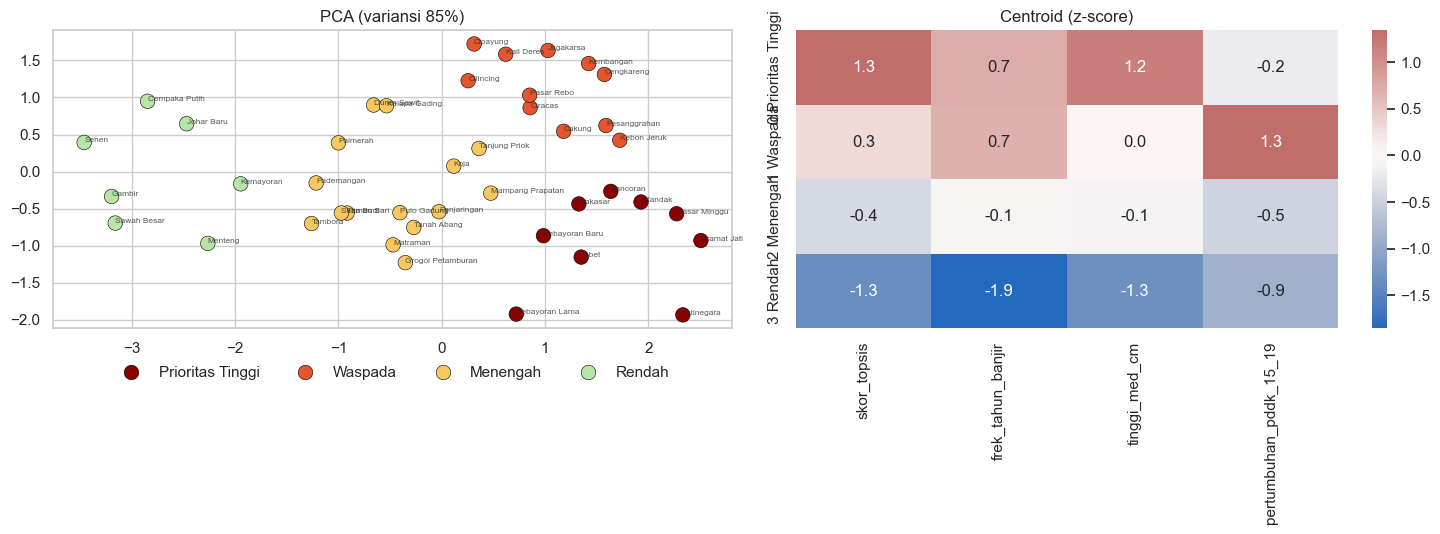

In [ ]:
P = PCA(2, random_state=SEED).fit(Z); pc = P.transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(x=pc[:,0], y=pc[:,1], hue=res.cluster_name.values, palette=COLORS, hue_order=LABEL, s=110, edgecolor="black", linewidth=.4, ax=ax[0])
for i, n in enumerate(res.index): ax[0].annotate(n.title(), (pc[i,0], pc[i,1]), fontsize=6, alpha=.75)
ax[0].set_title(f"PCA (variansi {P.explained_variance_ratio_.sum():.0%})"); ax[0].legend(loc="upper center", bbox_to_anchor=(.5, -0.08), ncol=K_FINAL, frameon=False)
cen = pd.DataFrame(centers, columns=Z.columns, index=[f"{i} {LABEL[i]}" for i in range(K_FINAL)])
sns.heatmap(cen, annot=True, fmt=".1f", cmap="vlag", center=0, ax=ax[1]); ax[1].set_title("Centroid (z-score)")
plt.tight_layout(); plt.savefig(FIG/"cluster_pca_centroid.png", dpi=200); plt.show()

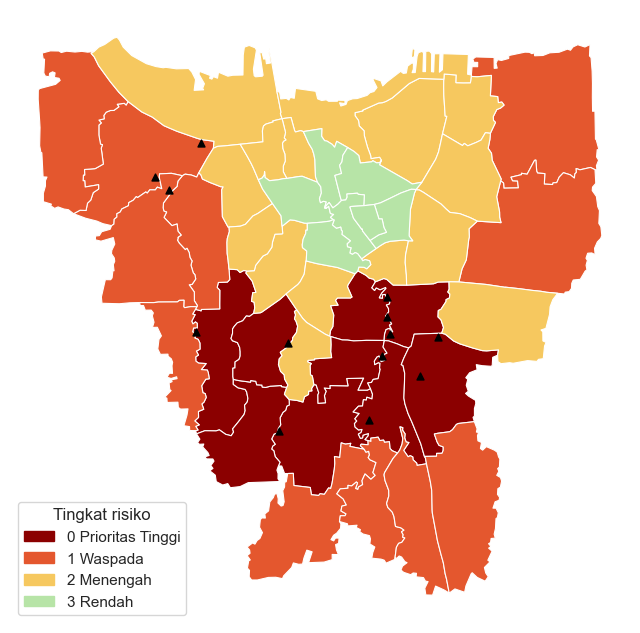

In [ ]:
from matplotlib.patches import Patch
pol = gpd.read_file(DATA/"interim/kecamatan_poly.geojson").merge(res.reset_index()[["kecamatan","cluster_name"]], on="kecamatan", how="left")
fig, ax = plt.subplots(figsize=(8, 8))
for name in LABEL: pol[pol.cluster_name == name].plot(ax=ax, color=COLORS[name], edgecolor="white", linewidth=.8)
pol[pol.cluster_name.isna()].plot(ax=ax, color="lightgrey", edgecolor="white")
al = pd.read_csv(DATA/"interim/alat_dini_titik.csv"); gpd.GeoDataFrame(al, geometry=gpd.points_from_xy(al.lon, al.lat), crs=4326).plot(ax=ax, color="black", marker="^", markersize=25)
ax.legend(handles=[Patch(color=COLORS[n], label=f"{i} {n}") for i, n in enumerate(LABEL)], title="Tingkat risiko", loc="lower left"); ax.set_axis_off()
plt.savefig(FIG/"cluster_map.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Export

In [ ]:
out = res.reset_index()[["kecamatan","cluster_id","cluster_name","silhouette_sample","skor_topsis","rank_topsis"]].sort_values("rank_topsis")
out.to_csv(DATA/"clustered_result.csv", index=False, encoding="utf-8")
res.to_csv(DATA/"interim/dki_master_clustered.csv", encoding="utf-8"); print(out.shape); out.head(10)

(42, 6)


,kecamatan,cluster_id,cluster_name,silhouette_sample,skor_topsis,rank_topsis
30,JATINEGARA,0,Prioritas Tinggi,0.495565,0.891560,1
31,KRAMAT JATI,0,Prioritas Tinggi,0.465278,0.817411,2
22,PASAR MINGGU,0,Prioritas Tinggi,0.408440,0.701585,3
25,TEBET,0,Prioritas Tinggi,0.502851,0.676798,4
21,PANCORAN,0,Prioritas Tinggi,0.285021,0.650613,5
0,CENGKARENG,1,Waspada,0.518862,0.611016,6
3,KEBON JERUK,1,Waspada,0.194954,0.589720,7
19,KEBAYORAN LAMA,0,Prioritas Tinggi,0.203006,0.585873,8
32,MAKASAR,0,Prioritas Tinggi,0.327952,0.579590,9
16,CILANDAK,0,Prioritas Tinggi,0.290008,0.578294,10
